# Carregando o Dataset

In [ ]:
import pandas as pd
import numpy as np


# Leitura do dataset
df = pd.read_csv("Dataset APAC - Página1.csv")
print(f"Dataset carregado com sucesso! Dimensões: {df.shape}")
df.head(3)

Dataset carregado com sucesso! Dimensões: (5104, 15)


,Código,Posto,Ano,Janeiro,Fevereiro,Março,Abril,Maio,Junho,Julho,Agosto,Setembro,Outubro,Novembro,Dezembro
0,198,Abreu e Lima,2010,"83,5","44,4","69,2","188,4","142,8","258,4","158,4","43,7","52,2","15,9","10,1","46,4"
1,290,Afogados da Ingazeira,2010,145,62,41,147,"1,5","74,7","17,5",-,-,"185,5",-,"29,5"
2,377,Afogados da Ingazeira (Açude Brotas),2010,"120,2","58,5","30,5",122,"1,5","72,7","15,7",-,-,"162,2",-,"37,4"


# Inserindo a informação de município e mesorregião

In [ ]:
import re

# 1. Função para extrair o nome da cidade a partir do Posto Pluviométrico
def extrair_cidade(posto):
    clean = re.sub(r'\(.*?\)', '', str(posto))
    clean = re.sub(r'-\s*PCD', '', clean, flags=re.IGNORECASE)
    clean = re.sub(r'-\s*APAC', '', clean, flags=re.IGNORECASE)
    return clean.split('-')[0].strip()

df['Cidade'] = df['Posto'].apply(extrair_cidade)

# 2. Dicionário de mapeamento completo dos municípios de PE para as 5 Mesorregiões
meso_map = {
    # Metropolitana do Recife
    'Abreu e Lima': 'Metropolitana do Recife', 'Araçoiaba': 'Metropolitana do Recife',
    'Cabo': 'Metropolitana do Recife', 'Cabo de Santo Agostinho': 'Metropolitana do Recife',
    'Camaragibe': 'Metropolitana do Recife', 'Igarassu': 'Metropolitana do Recife',
    'Itamaracá': 'Metropolitana do Recife', 'Ipojuca': 'Metropolitana do Recife',
    'Itapissuma': 'Metropolitana do Recife', 'Jaboatão': 'Metropolitana do Recife',
    'Jaboatão dos Guararapes': 'Metropolitana do Recife', 'Moreno': 'Metropolitana do Recife',
    'Olinda': 'Metropolitana do Recife', 'Paulista': 'Metropolitana do Recife',
    'Recife': 'Metropolitana do Recife', 'São Lourenço da Mata': 'Metropolitana do Recife',

    # Mata Pernambucana
    'Água Preta': 'Mata Pernambucana', 'Aliança': 'Mata Pernambucana', 'Amaraji': 'Mata Pernambucana',
    'Barreiros': 'Mata Pernambucana', 'Belém de Maria': 'Mata Pernambucana', 'Buenos Aires': 'Mata Pernambucana',
    'Camutanga': 'Mata Pernambucana', 'Carpina': 'Mata Pernambucana', 'Catende': 'Mata Pernambucana',
    'Chã de Alegria': 'Mata Pernambucana', 'Chã Grande': 'Mata Pernambucana', 'Condado': 'Mata Pernambucana',
    'Cortês': 'Mata Pernambucana', 'Escada': 'Mata Pernambucana', 'Feira Nova': 'Mata Pernambucana',
    'Ferreiros': 'Mata Pernambucana', 'Gameleira': 'Mata Pernambucana', 'Glória do Goitá': 'Mata Pernambucana',
    'Goiana': 'Mata Pernambucana', 'Itambé': 'Mata Pernambucana', 'Itaquitinga': 'Mata Pernambucana',
    'Jaqueira': 'Mata Pernambucana', 'Joaquim Nabuco': 'Mata Pernambucana', 'Lagoa do Carro': 'Mata Pernambucana',
    'Lagoa do Itaenga': 'Mata Pernambucana', 'Lagoa de Itaenga': 'Mata Pernambucana', 'Macaparana': 'Mata Pernambucana',
    'Machados': 'Mata Pernambucana', 'Maraial': 'Mata Pernambucana', 'Nazaré da Mata': 'Mata Pernambucana',
    'Palmares': 'Mata Pernambucana', 'Paudalho': 'Mata Pernambucana', 'Pombos': 'Mata Pernambucana',
    'Primavera': 'Mata Pernambucana', 'Quipapá': 'Mata Pernambucana', 'Ribeirão': 'Mata Pernambucana',
    'Rio Formoso': 'Mata Pernambucana', 'São Benedito do Sul': 'Mata Pernambucana',
    'São José da Coroa Grande': 'Mata Pernambucana', 'Sirinhaém': 'Mata Pernambucana',
    'Tamandaré': 'Mata Pernambucana', 'Timbaúba': 'Mata Pernambucana', 'Tracunhaém': 'Mata Pernambucana',
    'Vicência': 'Mata Pernambucana', 'Vitória de Santo Antão': 'Mata Pernambucana', 'Xexéu': 'Mata Pernambucana',

    # Agreste Pernambucano
    'Agrestina': 'Agreste Pernambucano', 'Alagoinha': 'Agreste Pernambucano', 'Altinho': 'Agreste Pernambucano',
    'Angelim': 'Agreste Pernambucano', 'Águas Belas': 'Agreste Pernambucano', 'Barra de Guabiraba': 'Agreste Pernambucano',
    'Belo Jardim': 'Agreste Pernambucano', 'Bezerros': 'Agreste Pernambucano', 'Bom Conselho': 'Agreste Pernambucano',
    'Bom Jardim': 'Agreste Pernambucano', 'Bonito': 'Agreste Pernambucano', 'Brejão': 'Agreste Pernambucano',
    'Brejo da Madre de Deus': 'Agreste Pernambucano', 'Buíque': 'Agreste Pernambucano', 'Cachoeirinha': 'Agreste Pernambucano',
    'Caetés': 'Agreste Pernambucano', 'Calçado': 'Agreste Pernambucano', 'Calçados': 'Agreste Pernambucano',
    'Camocim de São Felix': 'Agreste Pernambucano', 'Camocim de São Félix': 'Agreste Pernambucano', 'Canhotinho': 'Agreste Pernambucano',
    'Capoeiras': 'Agreste Pernambucano', 'Caruaru': 'Agreste Pernambucano', 'Casinhas': 'Agreste Pernambucano',
    'Correntes': 'Agreste Pernambucano', 'Cumaru': 'Agreste Pernambucano', 'Cupira': 'Agreste Pernambucano',
    'Frei Miguelinho': 'Agreste Pernambucano', 'Garanhuns': 'Agreste Pernambucano', 'Gravatá': 'Agreste Pernambucano',
    'Iati': 'Agreste Pernambucano', 'Ibirajuba': 'Agreste Pernambucano', 'Itaíba': 'Agreste Pernambucano',
    'Itaiba': 'Agreste Pernambucano', 'Jataúba': 'Agreste Pernambucano', 'Jatauba': 'Agreste Pernambucano',
    'João Alfredo': 'Agreste Pernambucano', 'Jucati': 'Agreste Pernambucano', 'Jupi': 'Agreste Pernambucano',
    'Jurema': 'Agreste Pernambucano', 'Lagoa do Ouro': 'Agreste Pernambucano', 'Lagoa dos Gatos': 'Agreste Pernambucano',
    'Lajedo': 'Agreste Pernambucano', 'Limoeiro': 'Agreste Pernambucano', 'Orobó': 'Agreste Pernambucano',
    'Palmeirina': 'Agreste Pernambucano', 'Panelas': 'Agreste Pernambucano', 'Paranatama': 'Agreste Pernambucano',
    'Passira': 'Agreste Pernambucano', 'Pedra': 'Agreste Pernambucano', 'Pesqueira': 'Agreste Pernambucano',
    'Poção': 'Agreste Pernambucano', 'Riacho das Almas': 'Agreste Pernambucano', 'Sairé': 'Agreste Pernambucano',
    'Salgadinho': 'Agreste Pernambucano', 'Saloá': 'Agreste Pernambucano', 'Sanharó': 'Agreste Pernambucano',
    'Santa Cruz do Capibaribe': 'Agreste Pernambucano', 'Santa Maria do Cambucá': 'Agreste Pernambucano',
    'Santa Maria do Cambuca': 'Agreste Pernambucano', 'São Bento do Una': 'Agreste Pernambucano',
    'São Caetano': 'Agreste Pernambucano', 'São João': 'Agreste Pernambucano', 'São Joaquim do Monte': 'Agreste Pernambucano',
    'São Vicente Férrer': 'Agreste Pernambucano', 'São Vicente Ferrer': 'Agreste Pernambucano', 'Surubim': 'Agreste Pernambucano',
    'Tacaimbó': 'Agreste Pernambucano', 'Taquaritinga do Norte': 'Agreste Pernambucano', 'Terezinha': 'Agreste Pernambucano',
    'Toritama': 'Agreste Pernambucano', 'Tupanatinga': 'Agreste Pernambucano', 'Venturosa': 'Agreste Pernambucano',
    'Vertente do Lério': 'Agreste Pernambucano', 'Vertentes': 'Agreste Pernambucano',

    # São Francisco Pernambucano
    'Belém de São Francisco': 'São Francisco Pernambucano', 'Cabrobó': 'São Francisco Pernambucano',
    'Carnaubeira da Penha': 'São Francisco Pernambucano', 'Floresta': 'São Francisco Pernambucano',
    'Jatobá': 'São Francisco Pernambucano', 'Lagoa Grande': 'São Francisco Pernambucano',
    'Orocó': 'São Francisco Pernambucano', 'Petrolândia': 'São Francisco Pernambucano',
    'Petrolina': 'São Francisco Pernambucano', 'Santa Maria da Boa Vista': 'São Francisco Pernambucano',
    'Tacaratu': 'São Francisco Pernambucano',

    # Sertão Pernambucano
    'Afogados da Ingazeira': 'Sertão Pernambucano', 'Afrânio': 'Sertão Pernambucano',
    'Araripina': 'Sertão Pernambucano', 'Arcoverde': 'Sertão Pernambucano', 'Betânia': 'Sertão Pernambucano',
    'Bodocó': 'Sertão Pernambucano', 'Brejinho': 'Sertão Pernambucano', 'Calumbi': 'Sertão Pernambucano',
    'Carnaíba': 'Sertão Pernambucano', 'Cedro': 'Sertão Pernambucano', 'Custódia': 'Sertão Pernambucano',
    'Dormentes': 'Sertão Pernambucano', 'Exu': 'Sertão Pernambucano', 'Flores': 'Sertão Pernambucano',
    'Granito': 'Sertão Pernambucano', 'Ibimirim': 'Sertão Pernambucano', 'Iguaracy': 'Sertão Pernambucano',
    'Iguaraci': 'Sertão Pernambucano', 'Inajá': 'Sertão Pernambucano', 'Ingazeira': 'Sertão Pernambucano',
    'Ipubi': 'Sertão Pernambucano', 'Itacuruba': 'Sertão Pernambucano', 'Itapetim': 'Sertão Pernambucano',
    'Manari': 'Sertão Pernambucano', 'Mirandiba': 'Sertão Pernambucano', 'Moreilândia': 'Sertão Pernambucano',
    'Ouricuri': 'Sertão Pernambucano', 'Parnamirim': 'Sertão Pernambucano', 'Quixaba': 'Sertão Pernambucano',
    'Salgueiro': 'Sertão Pernambucano', 'Santa Cruz': 'Sertão Pernambucano', 'Santa Filomena': 'Sertão Pernambucano',
    'Santa Cruz da Baixa Verde': 'Sertão Pernambucano', 'Santa Cruz da Venerada': 'Sertão Pernambucano',
    'Santa Terezinha': 'Sertão Pernambucano', 'São José do Belmonte': 'Sertão Pernambucano',
    'São José do Egito': 'Sertão Pernambucano', 'Serra Talhada': 'Sertão Pernambucano',
    'Serrita': 'Sertão Pernambucano', 'Sertânia': 'Sertão Pernambucano', 'Solidão': 'Sertão Pernambucano',
    'Tabira': 'Sertão Pernambucano', 'Terra Nova': 'Sertão Pernambucano', 'Trindade': 'Sertão Pernambucano',
    'Triunfo': 'Sertão Pernambucano', 'Tuparetama': 'Sertão Pernambucano', 'Verdejante': 'Sertão Pernambucano'
}

df['Mesorregiao'] = df['Cidade'].map(meso_map)

# 3. Limpeza dos valores numéricos dos meses
months = ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho',
          'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']

for m in months:
    df[m] = df[m].astype(str).str.strip().str.replace(',', '.')
    df[m] = pd.to_numeric(df[m], errors='coerce')

print("Distribuição das medições por Mesorregião:")
print(df['Mesorregiao'].value_counts())

Distribuição das medições por Mesorregião:
Mesorregiao
Sertão Pernambucano           1616
Agreste Pernambucano          1536
Mata Pernambucana             1056
Metropolitana do Recife        496
São Francisco Pernambucano     400
Name: count, dtype: int64


In [ ]:
# Unpivot / Melt para transformar os 12 meses em linhas
df_long = df.melt(
    id_vars=['Código', 'Posto', 'Cidade', 'Mesorregiao', 'Ano'],
    value_vars=months,
    var_name='Mes',
    value_name='Pluviometria'
)

# Mapear o nome do mês para valor numérico (1 a 12)
month_map = {m: i+1 for i, m in enumerate(months)}
df_long['Mes_Num'] = df_long['Mes'].map(month_map)

print(f"Dataset reestruturado para formato Long! Total de {len(df_long)} linhas.")
df_long.head(5)

Dataset reestruturado para formato Long! Total de 61248 linhas.


,Código,Posto,Cidade,Mesorregiao,Ano,Mes,Pluviometria,Mes_Num
0,198,Abreu e Lima,Abreu e Lima,Metropolitana do Recife,2010,Janeiro,83.5,1
1,290,Afogados da Ingazeira,Afogados da Ingazeira,Sertão Pernambucano,2010,Janeiro,145.0,1
2,377,Afogados da Ingazeira (Açude Brotas),Afogados da Ingazeira,Sertão Pernambucano,2010,Janeiro,120.2,1
3,549,Afogados da Ingazeira - PCD,Afogados da Ingazeira,Sertão Pernambucano,2010,Janeiro,NaN,1
4,1,Afrânio,Afrânio,Sertão Pernambucano,2010,Janeiro,84.6,1


# Gráficos de Análise do negoço

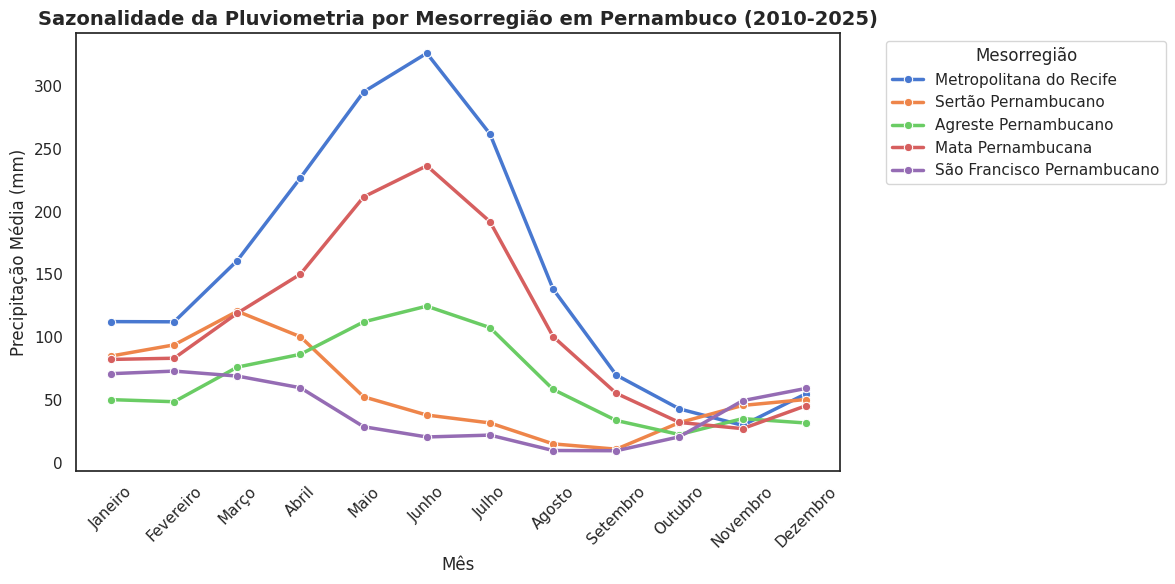

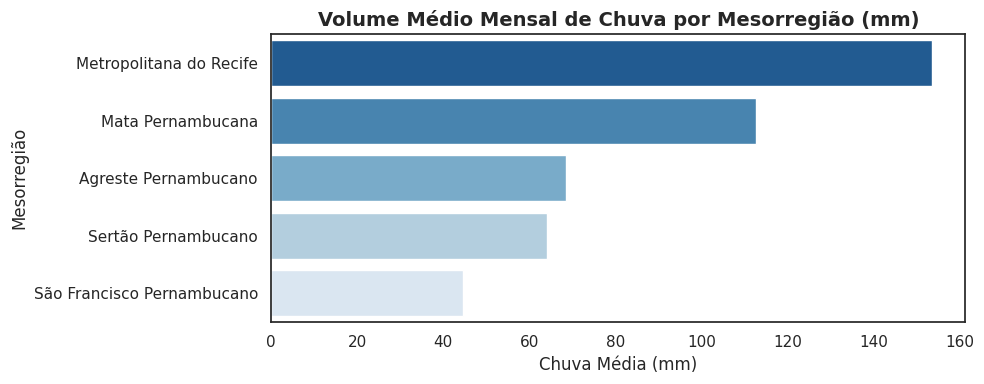

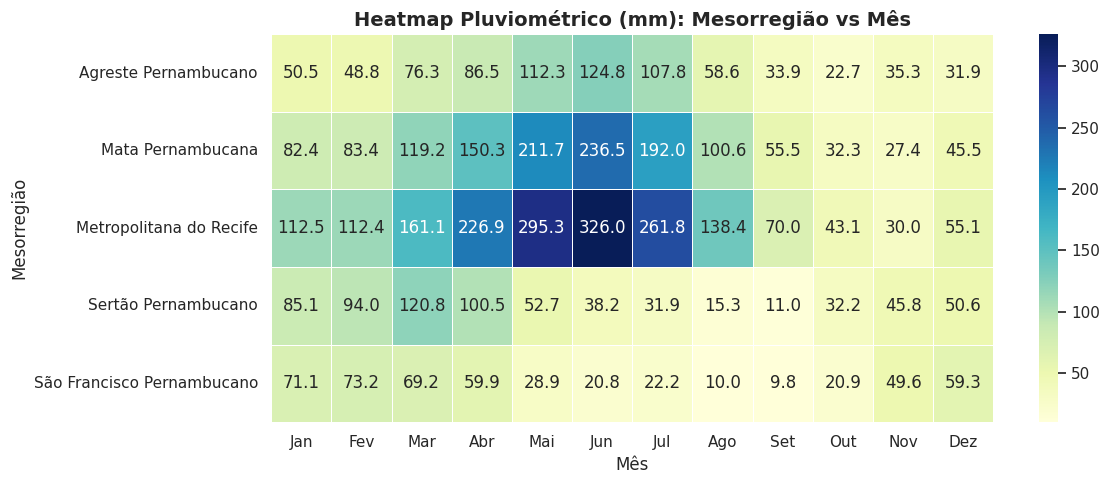

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", palette="muted")

# --- Gráfico 1: Sazonalidade da Pluviometria ao longo do ano por Mesorregião ---
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df_long,
    x='Mes',
    y='Pluviometria',
    hue='Mesorregiao',
    marker='o',
    errorbar=None,
    linewidth=2.5
)
plt.title("Sazonalidade da Pluviometria por Mesorregião em Pernambuco (2010-2025)", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Precipitação Média (mm)", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Mesorregião", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("\n"*10)
# --- Gráfico 2: Média Geral por Mesorregião ---
plt.figure(figsize=(10, 4))
avg_meso = df_long.groupby('Mesorregiao')['Pluviometria'].mean().reset_index().sort_values(by='Pluviometria', ascending=False)
sns.barplot(data=avg_meso, x='Pluviometria', y='Mesorregiao', hue = "Mesorregiao", palette='Blues_r', legend = False)
plt.title("Volume Médio Mensal de Chuva por Mesorregião (mm)", fontsize=14, fontweight='bold')
plt.xlabel("Chuva Média (mm)", fontsize=12)
plt.ylabel("Mesorregião", fontsize=12)
plt.tight_layout()
plt.show()


print("\n"*10)
# --- Gráfico 3: Heatmap Mesorregião por Mês do Ano ---
pivot_meso = df_long.groupby(['Mesorregiao', 'Mes_Num'])['Pluviometria'].mean().unstack()
pivot_meso.columns = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

plt.figure(figsize=(12, 5))
sns.heatmap(pivot_meso, cmap="YlGnBu", annot=True, fmt=".1f", linewidths=.5)
plt.title("Heatmap Pluviométrico (mm): Mesorregião vs Mês", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Mesorregião", fontsize=12)
plt.tight_layout()
plt.show()

# Representação gráfica das Instâncias

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar apenas os registros com medições válidas
df_valid = df_long.dropna(subset=['Pluviometria']).copy()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 7))

# Plotagem dos pontos com variação horizontal (jitter) e transparência (alpha)
sns.stripplot(
    data=df_valid,
    x='Mes',
    y='Pluviometria',
    hue='Mesorregiao',
    jitter=0.25,      # Espalhamento lateral dos pontos
    size=3,           # Tamanho dos pontos
    alpha=0.5,        # Transparência para ver alta densidade de acúmulo
    dodge=False        # Separa as mesorregiões lado a lado em cada mês (colocar para false para mostrar sobreposição)
)

plt.title("Distribuição Individual das Medições Pluviométricas por Mês e Mesorregião", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Precipitação (mm)", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Mesorregião", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

: 

# Ausência de dados por mesorregião

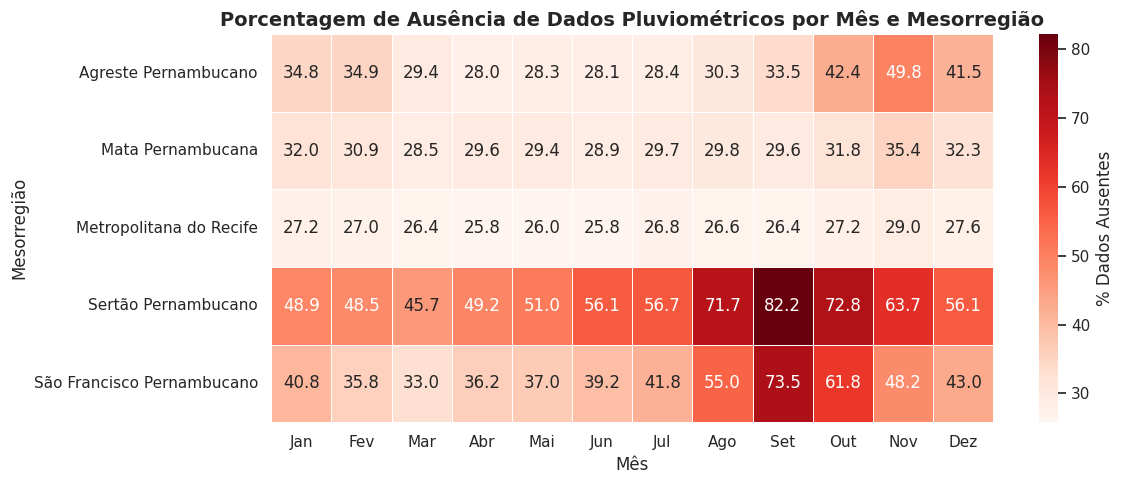

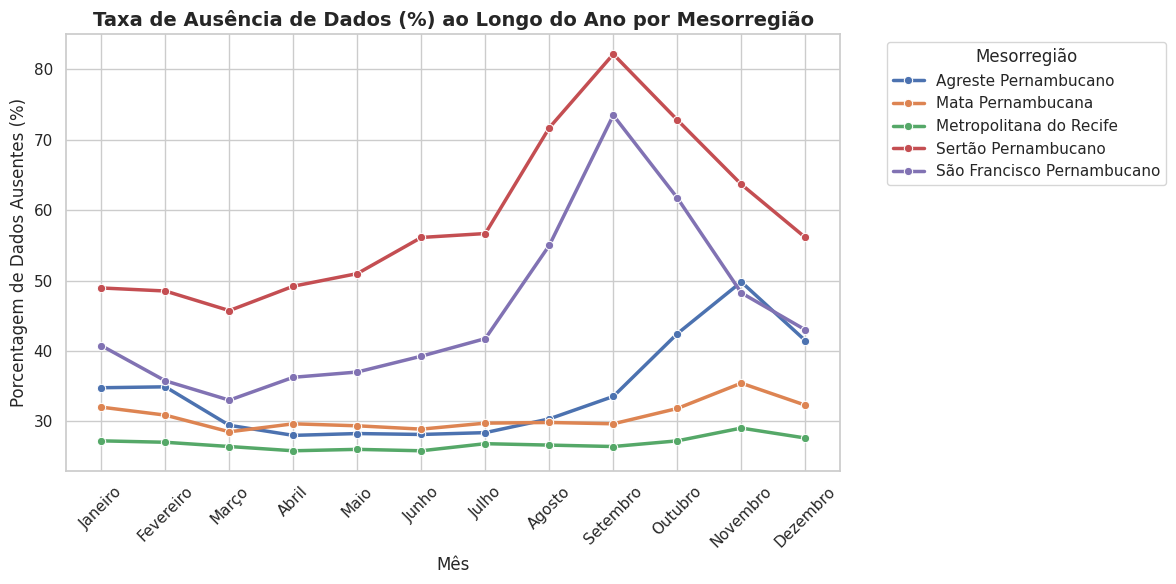

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Identificar registros ausentes na coluna Pluviometria
df_long['Ausente'] = df_long['Pluviometria'].isna()

# 2. Calcular a porcentagem de dados ausentes por Mesorregião e Mês
missing_df = df_long.groupby(['Mesorregiao', 'Mes', 'Mes_Num'])['Ausente'].mean().reset_index()
missing_df['Porcentagem_Ausente'] = missing_df['Ausente'] * 100

# Ordenar cronologicamente os meses
missing_df = missing_df.sort_values(by=['Mesorregiao', 'Mes_Num'])

# -------------------------------------------------------------
# GRÁFICO 1: Heatmap da Porcentagem de Ausência de Dados
# -------------------------------------------------------------
pivot_missing = missing_df.pivot(index='Mesorregiao', columns='Mes_Num', values='Porcentagem_Ausente')
pivot_missing.columns = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

plt.figure(figsize=(12, 5))
sns.heatmap(
    pivot_missing,
    cmap="Reds",
    annot=True,
    fmt=".1f",
    cbar_kws={'label': '% Dados Ausentes'},
    linewidths=.5
)
plt.title("Porcentagem de Ausência de Dados Pluviométricos por Mês e Mesorregião", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Mesorregião", fontsize=12)
plt.tight_layout()
plt.show()

print("\n"*10)
# -------------------------------------------------------------
# GRÁFICO 2: Linhas Comparativas da Ausência de Dados
# -------------------------------------------------------------
# Reordenar nomes dos meses no gráfico de linhas
months_order = ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho',
                'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=missing_df,
    x='Mes',
    y='Porcentagem_Ausente',
    hue='Mesorregiao',
    marker='o',
    linewidth=2.5
)
plt.title("Taxa de Ausência de Dados (%) ao Longo do Ano por Mesorregião", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Porcentagem de Dados Ausentes (%)", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Mesorregião", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Boxplots




/tmp/ipykernel_2647/3283098522.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


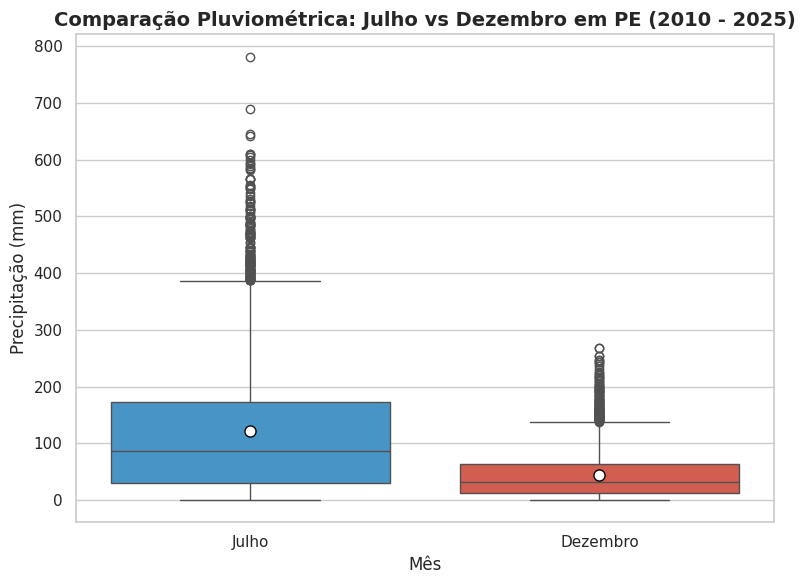

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar apenas os meses de Julho e Dezembro com dados válidos
df_jul_dez = df_long[df_long['Mes'].isin(['Julho', 'Dezembro'])].dropna(subset=['Pluviometria']).copy()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 6))

# Boxplot com marcador branco indicando a Média (mean) além da linha da Mediana
sns.boxplot(
    data=df_jul_dez,
    x='Mes',
    y='Pluviometria',
    palette={'Julho': '#3498db', 'Dezembro': '#e74c3c'},
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"}
)

plt.title("Comparação Pluviométrica: Julho vs Dezembro em PE (2010 - 2025)", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Precipitação (mm)", fontsize=12)
plt.tight_layout()
plt.show()